# Molecular property prediction: beginner tutorial **and graded homework**

Prof. Victor S. Batista

**CHEM 584: Introduction to Machine Learning and Quantum Computing**



**Big question:** Can a computer learn to estimate a molecule's lipophilicity (`logP`) from its chemical structure?

**No machine-learning background is assumed.** Read each explanation, run the small example, then run the main workflow. A machine-learning **model** is a mathematical rule that uses input information to produce a prediction. **Training** means adjusting that rule using examples for which the correct answer is already known.

### What students will learn
1. Work with a CSV file and a table of molecules; distinguish an **input** from the **target** being predicted.
2. Convert a SMILES chemical structure into numerical features called a **Morgan fingerprint**.
3. Separate molecules used for **training**, **validation**, and **testing**.
4. Understand how a neural network predicts a number, how **loss** measures errors, and how training improves its parameters.
5. Explain learning curves, assess prediction quality, make new predictions, and save a model.

**Teaching versus scientific evidence:** Without an uploaded CSV, this notebook uses a small **RDKit-calculated** logP example. It demonstrates the *workflow*, but it does not evaluate prediction of independently measured experimental logP. The small example also gives noisy, uncertain test statistics. Scientific conclusions require a substantially larger, appropriate dataset and careful splitting.

### How to use this notebook
- Run cells **in order** (`Runtime → Run all` in Google Colab); change the optional file path only if you have your own dataset.
- Read **Concept**, **Worked example**, and **Check your understanding** boxes before inspecting the corresponding code.
- Complete the **YOUR TURN** prompts in the final assignment section, and add your answers to Markdown/code cells.
- Do not submit only screenshots: submit your executed `.ipynb` plus the requested prediction CSV.

**Estimated teaching sequence:** CSV data → features → prediction → loss → learning → evaluation → deployment. The optional advanced experiments are clearly labeled.

## 1. Understand the Colab file system

Colab runs Python on a **remote, often temporary computer**, not your laptop. `os.getcwd()` is the working folder (usually `/content`); `os.listdir()` tells you which files are there. Anything under `/content` can disappear when the runtime resets. A mounted Google Drive is more persistent, but mounting requires authorization.

Three ways to supply a CSV are explained below: **A. upload from your computer**, **B. use Google Drive**, or **C. run the built-in example**. You only need one of them.

In [ ]:
import os, sys, random
from pathlib import Path
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print('Python:', sys.version.split()[0])
print('Working directory:', os.getcwd())
print('Files in current directory:', os.listdir('.')[:20])
print('In Google Colab:', 'google.colab' in sys.modules)

Python: 3.13.18
Working directory: /content
Files in current directory: ['.config', 'sample_data']
In Google Colab: True


### First principles: what is a dataset?

A dataset is a collection of **examples**, usually one example per row. In this notebook, **one row = one molecule**. A *column* holds one type of information: the molecule's SMILES string or its logP value.

| SMILES (structure) | logP (target) | What it means |
|---|---:|---|
| `CCO` | a number | Ethanol is the *input molecule*; its logP is the answer we want to predict. |
| `c1ccccc1` | a number | Benzene provides another learning example. |

**Inputs / features** (`X`) are what the model is allowed to see. The **target / label** (`y`) is the numeric value we want it to learn. `logP` describes partitioning between octanol and water; a higher value generally indicates greater preference for the organic phase. A model can learn a mapping $\hat y=f(X)$, where $\hat y$ is a predicted value.

**Check:** If a CSV has 100 molecules and two columns, is its number of *examples* 2 or 100? (Answer: 100.)

### Optional: upload a file from your computer

Run this cell **only** if you want to upload a CSV. Use the file chooser; the file will appear in `/content` and the cell will print its exact path. If you use the built-in example, **skip** this cell. The interactive upload does not persist across a Colab runtime reset.

In [ ]:
# OPTIONAL — uncomment the lines below in Google Colab to upload a file.
# from google.colab import files
# uploaded = files.upload()  # choose, e.g., 250k_zinc.csv
# print('Uploaded paths:', [str(Path('/content') / name) for name in uploaded])

### Optional: mount Google Drive and navigate to a folder

Click the authorization prompts only when running in your own Colab session. `drive.mount('/content/drive')` makes `MyDrive` available beneath `/content/drive/MyDrive`.

**Path troubleshooting:** a space in `Colab Notebooks` is part of the folder name; `Path.exists()` avoids confusing `FileNotFoundError` messages. It is usually clearer to use an absolute path than to change directories. The original notebook also illustrated `import mymodu`: an optional example is included after this cell.

In [ ]:
# OPTIONAL — only run if your files are stored in Google Drive.
# from google.colab import drive
# drive.mount('/content/drive')
# folder = Path('/content/drive/MyDrive/Colab Notebooks/ML')
# print('Exists:', folder.exists())
# if folder.exists():
#     print('Some files:', [p.name for p in folder.iterdir()][:20])
# CSV_PATH = folder / '250k_zinc.csv'  # specify this in Section 2, if desired

In [ ]:
# OPTIONAL — how to import a Python module mymodu.py from a folder.
# Suppose /content/drive/MyDrive/Colab Notebooks/ML/mymodu.py exists.
# import sys
# module_folder = '/content/drive/MyDrive/Colab Notebooks/ML'
# if module_folder not in sys.path:
#     sys.path.insert(0, module_folder)
# import mymodu
# print(mymodu.greeting)
# Do not run without your own mymodu.py file.

## 2. Install chemistry tools and choose the input data

`pandas` manages CSV tables, `RDKit` interprets molecules and computes fingerprints, `scikit-learn` handles splitting and metrics, and `PyTorch` trains the neural network. Colab usually includes most packages; we install only what is missing.

**CSV requirements:** a text column containing molecular SMILES (default `smiles`), and a numeric target column (default `logP`). The original file was called `250k_zinc.csv`. Set `CSV_PATH` to a file you uploaded or mounted; leave it as `None` to use the small reproducible instructional example.

In [ ]:
import importlib.util, subprocess
for import_name, pip_name in [('rdkit', 'rdkit'), ('torch', 'torch'), ('sklearn', 'scikit-learn'), ('matplotlib', 'matplotlib')]:
    if importlib.util.find_spec(import_name) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name])

from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, rdFingerprintGenerator
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('RDKit available; PyTorch', torch.__version__, '| device:', DEVICE)

RDKit available; PyTorch 2.11.0+cpu | device: cpu


### Worked example: reading a tiny CSV without chemistry or machine learning

In Python, `pandas` loads comma-separated files as **DataFrames** (tables). Before using your molecular dataset, inspect a three-row table. `head()` previews rows, `shape` returns *(rows, columns)*, and selecting `table['logP']` returns one column.

In [ ]:
toy_table = pd.DataFrame({'smiles': ['CCO', 'CCN', 'c1ccccc1'],
                            'logP': [-0.001, -0.035, 1.687]})
print('Example records:')
display(toy_table)
print('Rows, columns:', toy_table.shape)
print('Target values:', toy_table['logP'].to_list())
# These numbers are illustrative; they are not read from the uploaded dataset.

Example records:


,smiles,logP
0,CCO,-0.001
1,CCN,-0.035
2,c1ccccc1,1.687


Rows, columns: (3, 2)
Target values: [-0.001, -0.035, 1.687]


In [ ]:
# === EDIT THESE SETTINGS FOR YOUR DATA ===
CSV_PATH = None  # Example: '/content/250k_zinc.csv' or '/content/drive/MyDrive/ML/250k_zinc.csv'
SMILES_COLUMN = 'smiles'
TARGET_COLUMN = 'logP'
MAX_ROWS = 20000  # keep first 20,000 records for an accessible Colab lesson; set None for all

# If a file named 250k_zinc.csv has already been uploaded to /content, find it automatically.
if CSV_PATH is None and Path('/content/250k_zinc.csv').exists():
    CSV_PATH = '/content/250k_zinc.csv'

if CSV_PATH is not None:
    path = Path(CSV_PATH).expanduser()
    if not path.is_file():
        raise FileNotFoundError(f'CSV not found: {path}. Check the upload/Drive path above.')
    df_raw = pd.read_csv(path, nrows=MAX_ROWS)
    source_description = f'User CSV: {path}'
else:
    # Instructional demonstration only: RDKit logP is the label, not a measured assay value.
    # Creating variations across ordinary small drug-like molecules makes this notebook runnable.
    smiles_examples = [
        'CCO','CCCO','CCCCO','CCCCCO','CC(=O)O','CCC(=O)O','CCN','CCCN',
        'CCOC','CCOCC','CC(=O)N','CC(C)O','CC(C)CO','CC(C)(C)O',
        'c1ccccc1','Cc1ccccc1','CCc1ccccc1','Oc1ccccc1','COc1ccccc1',
        'Nc1ccccc1','Clc1ccccc1','Brc1ccccc1','Fc1ccccc1',
        'c1ccncc1','c1ccoc1','c1ccsc1','CC1CCCCC1','C1CCCCC1',
        'CCN(CC)CC','CC(=O)OC','CCOC(=O)C','CC(C)C','CCCCC',
        'CCCCCC','CCCCCCC','CC(C)CC','CC(C)(C)C','CO','CN',
        'NCCO','OCCO','NCCN','CNC','CCNC','CC(=O)OC(C)C',
        'CC(C)C(=O)O','c1ccc(CO)cc1','c1ccc(CCO)cc1','CCc1ccncc1',
        'CC(=O)c1ccccc1','CCOc1ccccc1','CCNc1ccccc1','OCc1ccccc1',
        'CC(C)N','CCC(C)O','CCCCN','CCCCCN','CCCCl','CCCCCl',
        'CCBr','CCCBr','CCF','CCCF','CC#N','CCC#N'
    ]
    records = []
    for s in smiles_examples:
        mol = Chem.MolFromSmiles(s)
        if mol is not None:
            canonical = Chem.MolToSmiles(mol)
            records.append({'smiles': canonical, 'logP': Descriptors.MolLogP(mol)})
    df_raw = pd.DataFrame(records).drop_duplicates('smiles').reset_index(drop=True)
    source_description = 'RDKit-calculated instructional example (NOT experimental data)'
print(source_description)
print('Shape (rows, columns):', df_raw.shape)
display(df_raw.head())

RDKit-calculated instructional example (NOT experimental data)
Shape (rows, columns): (64, 2)


,smiles,logP
0,CCO,-0.0014
1,CCCO,0.3887
2,CCCCO,0.7788
3,CCCCCO,1.1689
4,CC(=O)O,0.0909


### How to read a DataFrame

`df.head()` prints the first five rows; `df.columns` gives the column names; `df.shape` gives `(number of rows, number of columns)`; `df.isna().sum()` counts missing entries. Access a named column with `df['logP']` rather than assuming it is column number 1.

**Try:** intentionally change `TARGET_COLUMN` to an incorrect name, observe the informative error, and restore it.

In [ ]:
print('Columns:', df_raw.columns.tolist())
print('Missing values in each column:')
print(df_raw.isna().sum())
required = {SMILES_COLUMN, TARGET_COLUMN}
missing = required - set(df_raw.columns)
if missing:
    raise ValueError(f'Missing columns: {sorted(missing)}. Available columns: {df_raw.columns.tolist()}')
print('First three targets:', df_raw[TARGET_COLUMN].head(3).tolist())

Columns: ['smiles', 'logP']
Missing values in each column:
smiles    0
logP      0
dtype: int64
First three targets: [-0.0014000000000000123, 0.3887, 0.7787999999999999]


## 3. Validate structures, clean targets, visualize labels

**SMILES** are strings describing molecular connectivity, not yet suitable as NN inputs. RDKit parses each string into a molecular graph. We remove invalid SMILES, missing/non-numeric targets, and repeated canonical SMILES so identical molecules cannot land in different splits. **Important:** if duplicated molecules have different measured targets, choose a scientifically justified aggregation policy rather than blindly keeping the first record (this tutorial keeps the first and reports how many were removed).

### Why clean molecular data?

Computers cannot learn reliably from an unreadable chemical structure or an unknown target. **SMILES** encodes atoms and bonds as text (for example, `CCO` for ethanol). RDKit checks whether SMILES is chemically parseable and can write a **canonical SMILES**: a standardized text form for the same molecular graph. Duplicates can cause a molecule to appear multiple times and distort evaluation.

**Worked example:** If a table has 100 molecules, 5 invalid SMILES, and 3 repeated valid structures, we would retain **92 distinct valid examples** if those counts do not overlap. We should also remove missing/non-numeric logP values; exact counts depend on the actual data.

**Think before running:** Should a string like `NOT_A_MOLECULE` be assigned a fingerprint of all zeros? **No**: an invalid molecular structure is not an actual measured molecule and must be flagged or excluded.

In [ ]:
work = df_raw[[SMILES_COLUMN, TARGET_COLUMN]].copy()
work[TARGET_COLUMN] = pd.to_numeric(work[TARGET_COLUMN], errors='coerce')
work = work.dropna(subset=[SMILES_COLUMN, TARGET_COLUMN]).copy()
work = work[np.isfinite(work[TARGET_COLUMN])].copy()
work[SMILES_COLUMN] = work[SMILES_COLUMN].astype(str).str.strip()

canonical = []
for s in work[SMILES_COLUMN]:
    mol = Chem.MolFromSmiles(s)
    canonical.append(Chem.MolToSmiles(mol) if mol is not None else None)
work['canonical_smiles'] = canonical
invalid_count = work['canonical_smiles'].isna().sum()
work = work.dropna(subset=['canonical_smiles'])
dup_count = work.duplicated(subset='canonical_smiles').sum()
work = work.drop_duplicates('canonical_smiles').reset_index(drop=True)
print(f'Kept {len(work):,} valid, distinct molecules; excluded {invalid_count} invalid SMILES and {dup_count} duplicates.')
if len(work) < 20:
    raise ValueError('Need at least 20 valid distinct molecules for this teaching example.')
display(work.head())

Kept 64 valid, distinct molecules; excluded 0 invalid SMILES and 0 duplicates.


,smiles,logP,canonical_smiles
0,CCO,-0.0014,CCO
1,CCCO,0.3887,CCCO
2,CCCCO,0.7788,CCCCO
3,CCCCCO,1.1689,CCCCCO
4,CC(=O)O,0.0909,CC(=O)O


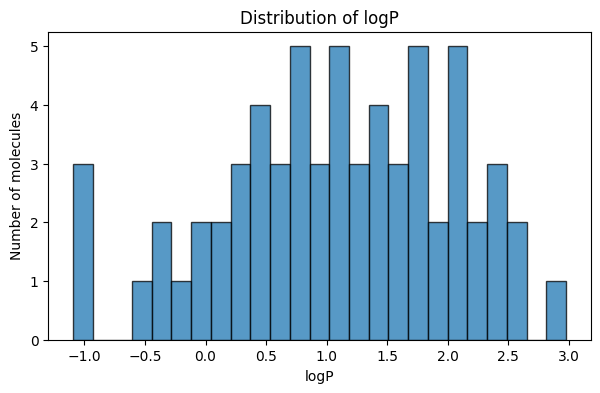

count    64.000000
mean      1.082964
std       0.950721
min      -1.096200
25%       0.457925
50%       1.152100
75%       1.799900
max       2.976700


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(work[TARGET_COLUMN], bins=25, edgecolor='black', alpha=0.75)
ax.set(xlabel=TARGET_COLUMN, ylabel='Number of molecules', title=f'Distribution of {TARGET_COLUMN}')
plt.show()
print(work[TARGET_COLUMN].describe().to_string())

## 4. Molecular representation: SMILES → Morgan fingerprints

A neural network expects a fixed-length vector of numbers. A **Morgan fingerprint** hashes local atomic neighborhoods into a binary vector. Here `radius=2` (roughly ECFP4 neighborhoods) and `fpSize=2048`. Each bit indicates whether certain hashed local patterns occur (collisions are possible). Two similar molecules will often share many bits, but fingerprint bits do not represent measured quantities.

**Shape check:** for `N` molecules, `X.shape == (N, 2048)`; the regression target has shape `(N, 1)`.

### From a molecule to numbers: what is a feature vector?

A neural network works with numbers, not directly with characters in a SMILES string. A **feature vector** is a fixed-size collection of numerical descriptions of an example. For everyday objects, features might be height and weight; for molecules, they can describe structural patterns.

A **Morgan fingerprint** examines an atom's local connectivity, expands the surrounding neighborhood outward, and hashes the observed environments into positions of a binary vector. A binary value is **0** (bit not set) or **1** (bit set). With `radius=2`, the local environments extend two bonds from their central atoms. With `FP_BITS=2048`, *every molecule* has 2048 output entries, even if the molecules contain different numbers of atoms.

**Small analogy (not an actual molecular fingerprint):** Suppose we track only four illustrative patterns: `[aromatic ring, oxygen, nitrogen, chlorine]`. Ethanol might be `[0,1,0,0]`, while aniline might be `[1,0,1,0]`. Real Morgan bits encode **hashed atom neighborhoods**, not these hand-labeled functional groups; multiple patterns may map to the same bit (a **collision**).

**What is `X`?** Stack the feature vectors into a rectangular array: *rows are molecules* and *columns are fingerprint bits*. With 60 molecules and 2048 bits, the array has shape `(60, 2048)`. **What is `y`?** A column of 60 numeric targets with shape `(60, 1)`.

**Check:** Does a 1 in fingerprint position 75 mean “75 atoms”? No. It only means a structural environment activated that bit.

In [ ]:
FP_BITS = 2048
FP_RADIUS = 2
fp_generator = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS, fpSize=FP_BITS)

def smiles_to_fingerprint(smiles):
    """Return a 2048-element float32 vector, or None for invalid SMILES."""
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return None
    fp = fp_generator.GetFingerprint(mol)
    bits = np.zeros(FP_BITS, dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, bits)
    return bits.astype(np.float32)

example = work['canonical_smiles'].iloc[0]
print('Example SMILES:', example)
print('Fingerprint shape:', smiles_to_fingerprint(example).shape)
print('Number of active bits:', int(smiles_to_fingerprint(example).sum()))

X = np.stack([smiles_to_fingerprint(s) for s in work['canonical_smiles']])
y = work[TARGET_COLUMN].to_numpy(dtype=np.float32).reshape(-1, 1)
smiles_clean = work['canonical_smiles'].to_numpy()
print('X shape:', X.shape, '| y shape:', y.shape)

Example SMILES: CCO
Fingerprint shape: (2048,)
Number of active bits: 6
X shape: (64, 2048) | y shape: (64, 1)


In [ ]:
# VISUAL CHECK: inspect a real fingerprint *before* the larger array is built.
small_example_smiles = 'CCO'
small_fp = smiles_to_fingerprint(small_example_smiles)
print('SMILES:', small_example_smiles)
print('First 24 bits:', small_fp[:24].astype(int).tolist())
print('Number of on bits:', int(small_fp.sum()), 'out of', len(small_fp))
print('Array shape:', small_fp.shape)
# Most entries are 0; an on bit indicates a hashed neighborhood.

SMILES: CCO
First 24 bits: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Number of on bits: 6 out of 2048
Array shape: (2048,)


## 5. Split first: training, validation, and untouched test data

- **Training** (70%): gradient descent changes the NN weights.
- **Validation** (15%): compare hyperparameters, select an epoch, and watch for overfitting.
- **Test** (15%): evaluate once after choices are finished.

We fit the `StandardScaler` to **training targets only**. Using test-set statistics during preprocessing would leak information. This is a **random-molecule split**, which tends to be optimistic when molecules share scaffolds; a scaffold split is recommended for more stringent chemistry evaluation. Small datasets have noisy metrics.

### Why three separate datasets?

Imagine practicing for a chemistry exam with worked problems. The **training set** is the practice material used to change the model's weights. The **validation set** is the practice quiz used to choose the best model or training duration. The **test set** is the *final exam*: it must not guide model choice.

This notebook uses roughly **70% training, 15% validation, and 15% testing**. Splitting is random but reproducible with `random_state=SEED`. We also standardize the training targets:

$$y_{\mathrm{scaled}} = \frac{y-\mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}}.$$

**Why?** Bringing values to a convenient scale can make neural-network optimization more stable. For example, if the training mean is 2.0 and standard deviation is 0.5, a logP of 3.0 becomes `(3.0 − 2.0)/0.5 = 2.0`. The model predicts on this standardized scale during training; we convert back to logP for reporting.

**Critical rule:** Fit the mean and standard deviation **only on training targets**, then apply that same transformation to validation and test data. Otherwise evaluation information leaks into training. A random molecular split is a teaching baseline; closely related molecules or duplicate chemical identities can still make it optimistic. Scaffold splits are a more demanding optional extension.

In [ ]:
# Hand calculation: understand target standardization.
toy_mean, toy_std, toy_logp = 2.0, 0.5, 3.0
scaled_demo = (toy_logp - toy_mean) / toy_std
restored_demo = scaled_demo * toy_std + toy_mean
print('Original:', toy_logp, '| standardized:', scaled_demo,
      '| converted back:', restored_demo)

Original: 3.0 | standardized: 2.0 | converted back: 3.0


In [ ]:
indices = np.arange(len(X))
idx_trainval, idx_test = train_test_split(indices, test_size=0.15, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.15/0.85, random_state=SEED)
print('Train/validation/test sizes:', len(idx_train), len(idx_val), len(idx_test))
assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test) or set(idx_val) & set(idx_test))

scaler = StandardScaler()
y_train_scaled = scaler.fit_transform(y[idx_train]).astype(np.float32)
y_val_scaled = scaler.transform(y[idx_val]).astype(np.float32)
y_test_scaled = scaler.transform(y[idx_test]).astype(np.float32)

def make_loader(indices, scaled_targets, shuffle=False, batch_size=64):
    dataset = TensorDataset(torch.from_numpy(X[indices]), torch.from_numpy(scaled_targets))
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(idx_train, y_train_scaled, shuffle=True)
val_loader = make_loader(idx_val, y_val_scaled)
test_loader = make_loader(idx_test, y_test_scaled)
print('Training-only target mean and SD:', float(scaler.mean_[0]), float(scaler.scale_[0]))

Train/validation/test sizes: 44 10 10
Training-only target mean and SD: 1.1157995505597105 1.009177982121645


## 6. Build the neural network, one component at a time

For fingerprint vector **x** with 2,048 features, a fully connected layer computes `z = Wx + b`; `ReLU(z) = max(z, 0)` adds nonlinearity. Repeated layers learn combinations of fingerprint features. `Dropout` randomly removes hidden activations **during training only** to regularize the model. A final layer with **one output** predicts a standardized continuous logP value.

We optimize mean-squared error (MSE) using Adam. `loss.backward()` computes gradients by backpropagation; `optimizer.step()` updates weights. A model with more parameters can fit more complicated patterns but is not guaranteed to generalize better.

### Neural networks without jargon

Start with a simpler predictor, a **weighted sum**:

$$\hat y = w_1 x_1 + w_2 x_2 + b.$$

Here `x1` and `x2` are feature values, `w1` and `w2` are **weights** learned from data, and `b` is the **bias/intercept**. The bias lets the predicted value be nonzero even when both features are zero. For example, with `x=[1,0]`, `w=[0.4,−0.2]`, and `b=0.1`, the prediction is `0.4×1 + (−0.2)×0 + 0.1 = 0.5`.

A neural network stacks many weighted sums into **layers**. Each hidden layer applies a nonlinearity like **ReLU**: `ReLU(z)=max(z,0)`. This allows learning relationships more flexible than a single straight-line rule. **Dropout** temporarily hides some hidden outputs during training to discourage excessive reliance on individual pathways. The last layer emits **one number** because logP prediction is **regression** (predicting a continuous value), not classification.

**Important:** Morgan fingerprint bits are not individually interpretable measured physicochemical properties. A large network can overfit a small dataset; more parameters do not guarantee better generalization.

In [ ]:
# WORKED EXAMPLE: weighted sum, intercept, and ReLU.
toy_features = np.array([1.0, 0.0])
toy_weights = np.array([0.4, -0.2])
toy_bias = 0.1
z = np.dot(toy_features, toy_weights) + toy_bias
print('Weighted sum plus bias:', z)
print('ReLU output:', max(0.0, z))
print('With both input features zero, output before ReLU is still:', toy_bias)

Weighted sum plus bias: 0.5
ReLU output: 0.5
With both input features zero, output before ReLU is still: 0.1


In [ ]:
def make_model(hidden_dims=(128, 64), dropout=0.10):
    layers = []
    previous = FP_BITS
    for width in hidden_dims:
        layers += [nn.Linear(previous, width), nn.ReLU()]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        previous = width
    layers.append(nn.Linear(previous, 1))  # regression output: no sigmoid
    return nn.Sequential(*layers)

def count_parameters(network):
    return sum(p.numel() for p in network.parameters() if p.requires_grad)

model = make_model(hidden_dims=(128, 64), dropout=0.10).to(DEVICE)
print(model)
print('Trainable parameters:', f'{count_parameters(model):,}')
first_batch_x, first_batch_y = next(iter(train_loader))
with torch.no_grad():
    print('One batch:', first_batch_x.shape, '→ predictions:', model(first_batch_x.to(DEVICE)).shape)

Sequential(
  (0): Linear(in_features=2048, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.1, inplace=False)
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.1, inplace=False)
  (6): Linear(in_features=64, out_features=1, bias=True)
)
Trainable parameters: 270,593
One batch: torch.Size([44, 2048]) → predictions: torch.Size([44, 1])


## 7. Training and validation curves

An **epoch** is one pass through all training examples, divided into **mini-batches**. Each iteration follows: clear old gradients → predict → compute loss → backpropagate → update weights.

We track validation loss after each epoch **without using it for gradient updates**, keep the best-validation model in memory, and apply simple early stopping. Learning curves here use MSE on **standardized targets**, not logP units.

### How does a network learn? Loss and gradients from first principles

A **prediction error** is the difference between model prediction and known target. For continuous logP, we train using **mean squared error** (MSE):

$$\mathrm{MSE}=\frac{1}{N}\sum_{i=1}^N(\hat y_i-y_i)^2.$$

If two predictions are 1.5 and 2.0 and targets are 1.0 and 3.0, the errors are `0.5` and `−1.0`, so MSE is `(0.25+1.00)/2=0.625`. Squaring penalizes larger errors more strongly.

The **gradient** describes how the loss would change if we slightly changed each weight. An **optimizer** takes steps intended to reduce loss. Conceptually: `new weight = old weight − learning_rate × gradient`. The **learning rate** controls step size. PyTorch's `loss.backward()` computes gradients with automatic differentiation; `optimizer.step()` updates weights. This notebook uses **Adam**, an optimizer that adapts the steps for individual parameters.

An **epoch** is one complete pass through the training dataset; **mini-batches** divide that pass into smaller groups for efficient updates. **Early stopping** keeps the weights from the epoch with the best validation performance instead of automatically keeping the last epoch.

**Interpretation:** Training MSE decreasing while validation MSE increases is a warning sign of **overfitting**: the network memorizes patterns that do not help on new molecules.

In [ ]:
# WORKED EXAMPLE: calculate loss and perform one scalar gradient step.
example_targets = np.array([1.0, 3.0])
example_predictions = np.array([1.5, 2.0])
example_mse = np.mean((example_predictions - example_targets)**2)
print('MSE calculation:', example_mse, '(expected 0.625)')
# Toy objective L(w)=(w-3)^2 has derivative dL/dw=2*(w-3).
w, learning_rate = 0.0, 0.1
for step in range(5):
    gradient = 2 * (w - 3)
    w -= learning_rate * gradient
    print(f'Step {step+1}: w={w:.4f}, loss={(w-3)**2:.4f}')

MSE calculation: 0.625 (expected 0.625)
Step 1: w=0.6000, loss=5.7600
Step 2: w=1.0800, loss=3.6864
Step 3: w=1.4640, loss=2.3593
Step 4: w=1.7712, loss=1.5099
Step 5: w=2.0170, loss=0.9664


In [ ]:
def evaluate_scaled_mse(network, loader):
    network.eval()  # disables dropout
    total, n = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            total += nn.functional.mse_loss(network(xb), yb, reduction='sum').item()
            n += len(xb)
    return total / n

def fit_model(network, train_data, valid_data, epochs=40, lr=1e-3, patience=10, verbose=True):
    optimizer = torch.optim.Adam(network.parameters(), lr=lr)
    history = {'train': [], 'val': []}
    best_val = float('inf')
    best_weights = None
    stale = 0
    for epoch in range(epochs):
        network.train()
        total, n = 0.0, 0
        for xb, yb in train_data:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            predicted = network(xb)
            loss = nn.functional.mse_loss(predicted, yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
            n += len(xb)
        train_mse = total / n
        valid_mse = evaluate_scaled_mse(network, valid_data)
        history['train'].append(train_mse)
        history['val'].append(valid_mse)
        if valid_mse < best_val - 1e-6:
            best_val = valid_mse
            best_weights = {k: v.detach().cpu().clone() for k, v in network.state_dict().items()}
            best_epoch = epoch + 1
            stale = 0
        else:
            stale += 1
        if verbose and ((epoch + 1) % 5 == 0 or epoch == 0):
            print(f'Epoch {epoch+1:2d} | train MSE={train_mse:.4f} | val MSE={valid_mse:.4f}')
        if stale >= patience:
            break
    network.load_state_dict(best_weights)
    return history, best_epoch

EPOCHS = 40
history, best_epoch = fit_model(model, train_loader, val_loader, epochs=EPOCHS)
print(f'Best validation checkpoint from epoch {best_epoch}; epochs run: {len(history["train"])}')

Epoch  1 | train MSE=1.0089 | val MSE=0.7319
Epoch  5 | train MSE=0.9675 | val MSE=0.6893
Epoch 10 | train MSE=0.8925 | val MSE=0.6062
Epoch 15 | train MSE=0.7589 | val MSE=0.4839
Epoch 20 | train MSE=0.5729 | val MSE=0.3273
Epoch 25 | train MSE=0.3804 | val MSE=0.1817
Epoch 30 | train MSE=0.2318 | val MSE=0.1044
Epoch 35 | train MSE=0.1285 | val MSE=0.1186
Epoch 40 | train MSE=0.0872 | val MSE=0.1306
Best validation checkpoint from epoch 32; epochs run: 40


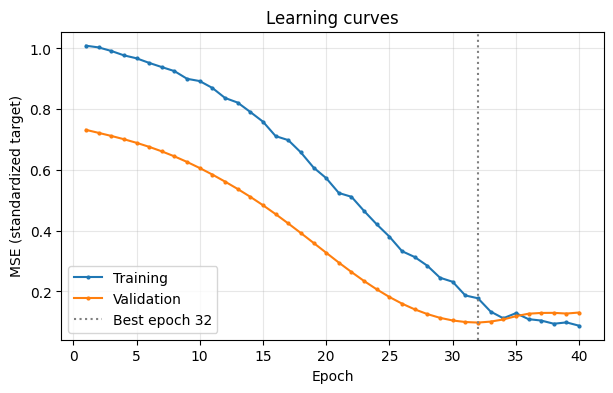

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(history['train']) + 1), history['train'], label='Training', marker='.', ms=4)
ax.plot(range(1, len(history['val']) + 1), history['val'], label='Validation', marker='.', ms=4)
ax.axvline(best_epoch, linestyle=':', color='gray', label=f'Best epoch {best_epoch}')
ax.set(xlabel='Epoch', ylabel='MSE (standardized target)', title='Learning curves')
ax.grid(alpha=0.3); ax.legend(); plt.show()

## 8. Final evaluation: test once, in physical logP units

We now use the **previously untouched** test set. The inverse transform converts the network output back from standardized values to the original logP scale. Report **MAE** (average absolute error), **RMSE** (typical error with extra weight on large mistakes), and **R²** (variance explained relative to predicting the test mean). A parity plot shows predicted versus reference values; the dashed diagonal represents ideal predictions.

Do **not** adjust architectures in response to test results: that would turn the test set into another validation set.

### What do the evaluation metrics tell us?

A trained regression model must make useful numerical predictions for **unseen** examples. After choosing the model using validation data, the held-out test set provides one final estimate of performance.

- **MAE (mean absolute error):** average size of errors, in logP units. For errors `+0.5` and `−1.0`, MAE is `(0.5+1.0)/2=0.75`.
- **RMSE (root mean squared error):** square root of MSE; larger mistakes count disproportionately. For those same errors, RMSE is `sqrt(0.625)≈0.791`.
- **R² (coefficient of determination):** compares squared prediction error with predicting the test-set mean; **1** is perfect, **0** matches that constant baseline, and **negative values are possible**.
- **Parity plot:** each point is one molecule, plotted as `(reference logP, predicted logP)`; closeness to the diagonal means agreement.

**Check:** An MAE of 0.5 does *not* mean 50% accuracy; it means an average absolute error of 0.5 **logP units**. Metrics on a tiny random test set are unstable, and high performance on calculated labels is not proof of experimental predictive accuracy.

In [ ]:
# Metric mini-example: compare MAE and RMSE by hand.
mini_true = np.array([1.0, 3.0])
mini_pred = np.array([1.5, 2.0])
print('MAE:', np.abs(mini_true - mini_pred).mean())
print('RMSE:', np.sqrt(np.mean((mini_true - mini_pred)**2)))

MAE: 0.75
RMSE: 0.7905694150420949


HELD-OUT test (10 molecules): MAE=0.407 logP | RMSE=0.483 logP | R²=0.550


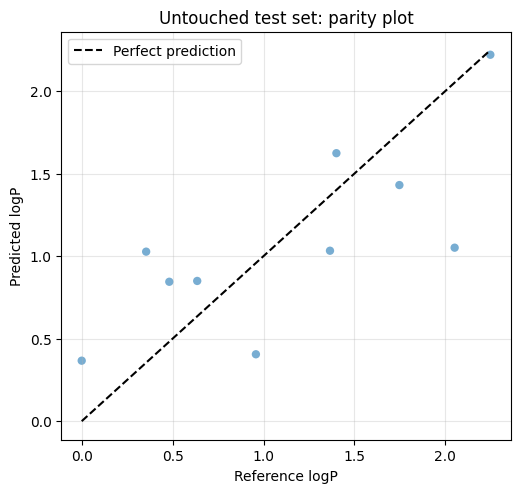

In [ ]:
def predict_fingerprints(network, fingerprint_array):
    network.eval()
    with torch.no_grad():
        batch = torch.from_numpy(np.asarray(fingerprint_array, dtype=np.float32)).to(DEVICE)
        pred_scaled = network(batch).cpu().numpy()
    return scaler.inverse_transform(pred_scaled).ravel()

y_reference = y[idx_test].ravel()
y_pred = predict_fingerprints(model, X[idx_test])
mae = mean_absolute_error(y_reference, y_pred)
rmse = np.sqrt(mean_squared_error(y_reference, y_pred))
r2 = r2_score(y_reference, y_pred)
print(f'HELD-OUT test ({len(idx_test)} molecules): MAE={mae:.3f} logP | RMSE={rmse:.3f} logP | R²={r2:.3f}')

fig, ax = plt.subplots(figsize=(5.8, 5.3))
ax.scatter(y_reference, y_pred, alpha=0.6, edgecolors='none')
lo = float(min(y_reference.min(), y_pred.min()))
hi = float(max(y_reference.max(), y_pred.max()))
ax.plot([lo, hi], [lo, hi], 'k--', label='Perfect prediction')
ax.set(xlabel='Reference logP', ylabel='Predicted logP', title='Untouched test set: parity plot')
ax.grid(alpha=0.3); ax.legend(); plt.show()

## 9. Predict new molecules from an input file and save a CSV

This is a complete inference workflow. You can set `NEW_CSV_PATH` to a CSV containing a `smiles` column (no `logP` column required). With `None`, the notebook creates a sample input file for practice. Invalid SMILES get an empty prediction and a `status` explaining why.

**Important:** predicting new SMILES requires the **same** fingerprint radius, bit count, and target scaler used for training. For truly novel chemotypes, predictions can be uncertain even if the test score looks good.

### Inference: using the model after training

**Training** requires known target values, but **inference** does not. Once trained, the network can take a new molecule's SMILES, generate its fingerprint using **exactly the same radius and bit length**, compute a scaled prediction, and convert it back to logP. The output CSV retains each input row and includes a prediction or an explicit invalid-SMILES status.

**Predicting is not validating:** The notebook cannot know the true logP of a new molecule unless an independent reference value is supplied. The output should be described as **model predictions**, not as measured values or guaranteed experimental estimates.

In [ ]:
NEW_CSV_PATH = None  # Example: '/content/my_new_molecules.csv'
if NEW_CSV_PATH is None:
    NEW_CSV_PATH = '/content/new_molecules_example.csv' if Path('/content').exists() else 'new_molecules_example.csv'
    pd.DataFrame({'smiles': ['CCO', 'CC(=O)O', 'c1ccccc1', 'INVALID_SMILES']}).to_csv(NEW_CSV_PATH, index=False)
    print('Created sample input:', NEW_CSV_PATH)

new_df = pd.read_csv(NEW_CSV_PATH)
if SMILES_COLUMN not in new_df:
    raise ValueError(f'Expected column {SMILES_COLUMN!r} in {NEW_CSV_PATH}')
new_df['predicted_logP'] = np.nan
new_df['status'] = 'invalid or missing SMILES'
valid_rows, new_fps = [], []
for index, smiles in new_df[SMILES_COLUMN].items():
    if pd.notna(smiles):
        fp = smiles_to_fingerprint(str(smiles))
        if fp is not None:
            valid_rows.append(index)
            new_fps.append(fp)
if new_fps:
    new_df.loc[valid_rows, 'predicted_logP'] = predict_fingerprints(model, np.stack(new_fps))
    new_df.loc[valid_rows, 'status'] = 'ok'
OUTPUT_CSV = 'molecular_logP_predictions.csv'
new_df.to_csv(OUTPUT_CSV, index=False)
print('Saved:', Path(OUTPUT_CSV).resolve())
display(new_df)
# Colab download: uncomment if you want a browser download dialog.
# from google.colab import files
# files.download(OUTPUT_CSV)

Created sample input: /content/new_molecules_example.csv
Saved: /content/molecular_logP_predictions.csv


[14:33:38] SMILES Parse Error: syntax error while parsing: INVALID_SMILES
[14:33:38] SMILES Parse Error: check for mistakes around position 3:
[14:33:38] INVALID_SMILES
[14:33:38] ~~^
[14:33:38] SMILES Parse Error: Failed parsing SMILES 'INVALID_SMILES' for input: 'INVALID_SMILES'


,smiles,predicted_logP,status
0,CCO,0.365528,ok
1,CC(=O)O,0.334153,ok
2,c1ccccc1,1.647260,ok
3,INVALID_SMILES,NaN,invalid or missing SMILES


## 10. Save and reload the model correctly

A `.pt` checkpoint stores learned weights **and** metadata needed at inference time: feature-generation settings, architecture, and target-scaling statistics. Files written to `/content` are temporary; download or copy the checkpoint into Google Drive to retain it. Only load checkpoints from trusted sources.

### Why save metadata as well as model weights?

Learned weights alone are not sufficient to reproduce predictions. To use a trained network later, you also need the **architecture** (how many neurons in each layer), **fingerprint settings** (radius/bit length), and **target scaler** (training mean and standard deviation). The checkpoint records them together, and the reload check confirms that loading gives the same output on example fingerprints. Keep training data provenance and software versions separately for robust scientific reproducibility.

In [ ]:
CHECKPOINT_PATH = 'morgan_logp_nn_checkpoint.pt'
hidden_dims = (128, 64)
dropout = 0.10
torch.save({
    'state_dict': {k: v.cpu().clone() for k, v in model.state_dict().items()},
    'hidden_dims': hidden_dims, 'dropout': dropout,
    'fp_radius': FP_RADIUS, 'fp_bits': FP_BITS,
    'target_mean': scaler.mean_.tolist(),
    'target_scale': scaler.scale_.tolist(),
    'target_name': TARGET_COLUMN,
}, CHECKPOINT_PATH)
print('Checkpoint saved:', Path(CHECKPOINT_PATH).resolve())

# Demonstrate round-trip reloading without touching the held-out test choices.
try:
    checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=True)
except TypeError:  # older PyTorch versions
    checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu')
restored = make_model(tuple(checkpoint['hidden_dims']), checkpoint['dropout'])
restored.load_state_dict(checkpoint['state_dict'])
restored = restored.to(DEVICE).eval()
with torch.no_grad():
    x_demo = torch.from_numpy(X[idx_test[:3]]).to(DEVICE)
    assert np.allclose(model(x_demo).cpu().numpy(), restored(x_demo).cpu().numpy(), atol=1e-6)
print('Reload check passed: same outputs before/after saving.')

Checkpoint saved: /content/morgan_logp_nn_checkpoint.pt
Reload check passed: same outputs before/after saving.


## 11. Optional experiment: model capacity versus overfitting

**Question:** Does a larger NN always give better predictions? Train several architectures with the **same train/validation split and scaled labels**. Plot their best training and validation errors against parameter count. We choose and compare architectures using **validation data only**; the test set stays untouched for this experiment.

This cell is **optional** (can take longer on CPU). Different dropout rates are held fixed to make parameter count the main architectural difference. A large model does **not automatically** overfit; look for a persistent train/validation gap. For rigorous scientific comparison, repeat with several random seeds and a more stringent split.

### Optional exploration: why might a bigger model perform worse?

A network with more hidden neurons can learn more complex functions but may also fit accidental details in its training set. **Model capacity** refers to its flexibility. This experiment compares architectures while holding the data split fixed. Change `RUN_CAPACITY_SWEEP=True` only if you want to spend additional Colab time; it is **not required for the basic workflow**. Compare **validation error**, not only training error, to make your model choice.

In [ ]:
# OPTIONAL: change RUN_CAPACITY_SWEEP to True to run the experiment.
RUN_CAPACITY_SWEEP = False
if RUN_CAPACITY_SWEEP:
    architectures = [(32,), (64, 32), (128, 64), (256, 128, 64), (512, 256, 128)]
    rows = []
    for dims in architectures:
        torch.manual_seed(SEED)
        candidate = make_model(dims, dropout=0.10).to(DEVICE)
        sweep_history, selected_epoch = fit_model(
            candidate, train_loader, val_loader, epochs=25, patience=7, verbose=False)
        # Training error of best checkpoint (not simply the last epoch)
        rows.append({'architecture': str(dims), 'parameters': count_parameters(candidate),
                     'train_mse': evaluate_scaled_mse(candidate, train_loader),
                     'val_mse': evaluate_scaled_mse(candidate, val_loader),
                     'best_epoch': selected_epoch})
    sweep = pd.DataFrame(rows).sort_values('parameters')
    display(sweep)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(sweep['parameters'], sweep['train_mse'], 'o-', label='Train MSE')
    ax.plot(sweep['parameters'], sweep['val_mse'], 's-', label='Validation MSE')
    ax.set_xscale('log')
    ax.set(xlabel='Trainable parameter count (log scale)', ylabel='Standardized MSE',
           title='NN capacity and generalization')
    ax.grid(alpha=0.3); ax.legend(); plt.show()
else:
    print('Capacity sweep skipped. Set RUN_CAPACITY_SWEEP=True to run it.')

Capacity sweep skipped. Set RUN_CAPACITY_SWEEP=True to run it.


# Graded homework: Molecular logP prediction (100 points)

Complete each task **in the notebook**. Include short written answers in Markdown cells, code cells showing calculations, and labeled figures. Unless your instructor supplies a different CSV, use the built-in calculated-logP dataset and explicitly identify it as **instructional**; do not present its results as experimental validation.

## Assignment 1 — Read and inspect molecular data (15 points)

**A1 (5 pt):** Explain in 3–5 sentences what one row in `df_raw` represents, what SMILES is, what `logP` represents, and which is `X` versus `y`. **Deliverable:** paragraph.

**A2 (5 pt):** Report `df_raw.shape`, list its columns, and display its first five rows. Explain what `shape` means. **Deliverable:** executed code + short answer.

**A3 (5 pt):** Report the number of valid distinct molecules after cleaning, the number of invalid SMILES and duplicates reported by the cleaning cell, and summarize the target histogram. **Deliverable:** counts, histogram, and 2–3 sentences.

## Assignment 2 — Molecular fingerprints and numerical features (20 points)

**B1 (8 pt):** Compute a fingerprint for ethanol (`CCO`) and benzene (`c1ccccc1`). Report array lengths, active-bit counts, and whether their bits are identical. **Deliverable:** code/output and interpretation.

**B2 (6 pt):** Explain in your own words what Morgan radius=2 and 2048 bits mean; explain why a 1 is *not* an atom count and why hashing can cause collisions. **Deliverable:** 4–6 sentences.

**B3 (6 pt):** Report the shapes of `X` and `y` and explain what each axis means. **Deliverable:** outputs and explanation.

## Assignment 3 — Splits, scaling, and data leakage (20 points)

**C1 (8 pt):** Report the exact training/validation/test sizes and explain the separate purpose of each. **Deliverable:** table or paragraph.

**C2 (6 pt):** Using the printed training mean and standard deviation, manually standardize a hypothetical logP of `3.0`; confirm your answer with code. **Deliverable:** equation, numerical result, code.

**C3 (6 pt):** Explain why the target scaler is fit only on the training data, and what may go wrong if you tune the model on test results. **Deliverable:** 4–6 sentences.

## Assignment 4 — Training and model assessment (30 points)

**D1 (8 pt):** Calculate MSE and MAE for targets `[1,3]` and predictions `[1.5,2]` without `sklearn`, then confirm in Python. **Deliverable:** hand calculation and code.

**D2 (8 pt):** Report the best validation epoch and describe training/validation loss trends. Explain whether the curves suggest overfitting. **Deliverable:** labeled learning-curve plot and 3–5 sentences.

**D3 (8 pt):** Report test MAE, RMSE and R², and interpret each, including what a negative R² would mean. **Deliverable:** executed metric output and 4–6 sentences.

**D4 (6 pt):** Explain two limitations of this demonstration (for example, RDKit-generated labels, small data, molecular similarity across random splits, or fingerprint information loss). **Deliverable:** paragraph.

## Assignment 5 — New molecules and scientific reporting (15 points)

**E1 (7 pt):** Generate a prediction CSV using at least **three valid** input SMILES and **one invalid** SMILES. Report which were accepted and how the invalid case was handled. **Deliverable:** executed prediction cell and `molecular_logP_predictions.csv`.

**E2 (5 pt):** Explain why new-molecule logP predictions are not automatically experimental measurements or proof of generalization. **Deliverable:** 3–5 sentences.

**E3 (3 pt):** State the name of the model checkpoint, and list at least three categories of metadata it preserves. **Deliverable:** short explanation.

## Grading rubric

| Section | Points | Basis for full credit |
|---|---:|---|
| 1. Data inspection | 15 | Correct outputs, basic terminology, clear histogram interpretation |
| 2. Fingerprint features | 20 | Correct calculations and conceptually accurate explanation |
| 3. Splitting and leakage | 20 | Correct sizes, scaling arithmetic, clear reasoning |
| 4. Training and evaluation | 30 | Correct loss calculations, labeled plots, sound assessment |
| 5. Inference and reporting | 15 | Working predictions CSV, invalid-input handling, scientific caveats |
| **Total** | **100** | |

**Partial credit:** Numerical/code tasks receive credit for a correct method even if a minor execution issue remains; interpretation points require written explanations. Figures must include meaningful axis labels. Unsupported conclusions about experimental predictive power lose interpretation credit.

### Submission checklist
- [ ] Submit this `.ipynb` with **all required cells executed** and written answers to A1–E3.
- [ ] Include figures for the label distribution, learning curves, and test parity plot.
- [ ] Attach `molecular_logP_predictions.csv` (with at least one invalid SMILES).
- [ ] State whether the targets came from the built-in **calculated** sample or your own dataset.
- [ ] Report the test-set metrics **once**, rather than repeatedly tuning on the test set.

### OPTIONAL extension (ungraded)
Use an independent, sufficiently large experimental dataset; compare fingerprint sizes or neural-network architectures using validation performance; then investigate **Bemis–Murcko scaffold splits**. Explain how a scaffold split differs from a random split and why it may be harder. Classification targets (e.g. toxicity yes/no) require a different output/loss and evaluation metrics; do not treat them as ordinary logP regression labels.


In [ ]:
# YOUR TURN — B1: fingerprints of ethanol and benzene.
# Fill the Markdown answers in a new cell below this one.
ethanol_fp = smiles_to_fingerprint('CCO')
benzene_fp = smiles_to_fingerprint('c1ccccc1')
print('Ethanol: length =', len(ethanol_fp), 'active bits =', int(ethanol_fp.sum()))
print('Benzene: length =', len(benzene_fp), 'active bits =', int(benzene_fp.sum()))
print('Are the bit vectors identical?', np.array_equal(ethanol_fp, benzene_fp))

Ethanol: length = 2048 active bits = 6
Benzene: length = 2048 active bits = 3
Are the bit vectors identical? False


In [ ]:
# YOUR TURN — C2 and D1: confirm your hand calculations.
hypothetical_logp = 3.0
print('C2 standardized 3.0 logP:', (hypothetical_logp - scaler.mean_[0]) / scaler.scale_[0])
true_values = np.array([1.0, 3.0]); predicted_values = np.array([1.5, 2.0])
print('D1 MSE:', np.mean((true_values - predicted_values) ** 2))
print('D1 MAE:', np.mean(np.abs(true_values - predicted_values)))

C2 standardized 3.0 logP: 1.8670645642496495
D1 MSE: 0.625
D1 MAE: 0.75


### Student written responses

Add Markdown cells immediately below this heading and label each response **A1**, **A2**, …, **E3**. For a coding task, place your code cell below its corresponding answer. When turning in the homework, keep the original worked examples and your completed cells together so the notebook runs from top to bottom.